<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 19: Housing Price Prediction






The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [76]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: VOcMGbXLUUBSxKdrtcGfAog7PNNg4nVDP6S453rbwGRqIsgyE14h0R90SpEB4z0VnWeceS6lymZjbvR4EipasFb+xHd6vq9Z
x-amz-request-id: CHFQ6HEWP45JQMFQ
Server: AmazonS3
Date: Sun, 01 Nov 2026 21:34:03 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [77]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Help investors evaluate whether what features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [78]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
from scipy import special

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [79]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [80]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [81]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [82]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [83]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [84]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [85]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [86]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [87]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [88]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [89]:
# Define the name of the feature columns to work with them independently

# Drop the target column from the feature column names
feature_cols = df.drop(columns=target_col, errors='ignore')

feature_cols.dtypes

,0
PID,int64
MS SubClass,int64
MS Zoning,object
Lot Frontage,float64
Lot Area,int64
...,...
Misc Val,int64
Mo Sold,int64
Yr Sold,int64
Sale Type,object


In [90]:
# Look for nulls in the features
(feature_cols.isnull().sum() / feature_cols.shape[0] * 100).sort_values(ascending=False)

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
...,...
Misc Val,0.000000
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000


In [91]:
feature_cols

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,Shed,500,10,2006,WD,Normal
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,126,0,NaN,NaN,NaN,0,12,2007,WD,Normal
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,7,2009,WD,Normal
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2009,WD,Normal
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal


#### Identifier Columns

In [92]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [93]:
# See proportion of unique values in the feature columns - highest is 1%
(feature_cols.nunique() / feature_cols.shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Garage Finish,0.113766
Paved Drive,0.113766
Alley,0.075844
Street,0.075844


### Backup #1

In [94]:
# Make a backup
df_bak1 = df.copy()

In [95]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

If equal to or greater than 90%, dropped columns.

If between 20-89%, imputed with the mode.

If between 0-19%, dropped the rows.

In [96]:
# Calculate the percentage of nulls in each feature column
null_percent = (feature_cols.isnull().sum() / df.shape[0] * 100).sort_values(ascending=False)

null_percent

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
...,...
Misc Val,0.000000
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000


Drop Columns

In [97]:
# Identify columns with 90% or greater nulls
cols_to_drop = null_percent[null_percent >= 90].index

In [98]:
# Rebuild feature_cols, keeping only columns below 90% nulls
feature_cols = [col for col in feature_cols if col not in cols_to_drop]

In [99]:
# Check the number of remaining features
print("Number of feature columns AFTER:", len(feature_cols))

Number of feature columns AFTER: 77


Impute

In [100]:
# Identify feature columns containing 40%-80% nulls
cols_to_impute = null_percent[
    (null_percent >= 20) & (null_percent <= 89)
].index.intersection(feature_cols)

# Impute nulls based on data type
for col in cols_to_impute:

    # Categorical features: impute with mode
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])

    # Numeric features (integers and floats): impute with median
    elif pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())

# Update feature_cols to include only the columns that still exist in df
feature_cols = df[feature_cols].columns

In [101]:
# Check the number of remaining features
print("Number of feature columns AFTER:", len(feature_cols))

Number of feature columns AFTER: 77


Drop Rows

In [102]:
# Verify the shape before dropping rows
df[feature_cols].shape

(2637, 77)

In [103]:
# Identify feature columns containing 0%-19% nulls
cols_to_drop_rows = null_percent[
    (null_percent > 0) & (null_percent <= 19)
].index.intersection(feature_cols)

# Drop rows containing nulls in those feature columns
df = df.dropna(subset=cols_to_drop_rows).reset_index(drop=True)

# Update feature_cols to reflect the remaining columns
feature_cols = [col for col in feature_cols if col in df.columns]

In [104]:
# Verify rows dropped
df[feature_cols].shape

(1984, 77)

In [105]:
# Verify no nulls in feature columns
df[feature_cols].isnull().sum().sort_values(ascending=False)

,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,0
Lot Area,0
...,...
Misc Val,0
Mo Sold,0
Yr Sold,0
Sale Type,0


### Backup #2

In [106]:
# Make a backup
df_bak2 = df.copy()

In [107]:
# Restore from backup
df = df_bak2.copy()

### Drop Identifier Column

In [108]:
# Drop the identifier column 'PID'
id_col = 'PID'

feature_cols = [col for col in feature_cols if col != id_col]

In [109]:
# Verify identifier column dropped
df[feature_cols].shape

(1984, 76)

### Backup #3

In [110]:
# Make a backup
df_bak3 = df.copy()

In [111]:
# Restore from backup
df = df_bak3.copy()

### Cleaned Data Frame

In [112]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [113]:
# Verify the working data frame
df_clean

,SalePrice,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,...,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Fence,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,115400,20,RL,62.0,14299,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,7,2007,WD,Normal
1,141000,50,RM,50.0,9000,Pave,Reg,Bnk,AllPub,Inside,...,0,0,126,0,MnPrv,0,12,2007,WD,Normal
2,254000,60,FV,68.0,7379,Pave,IR1,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,4,2010,WD,Normal
3,155000,70,RL,60.0,7200,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,4,2009,WD,Normal
4,125000,20,RL,70.0,8521,Pave,Reg,Lvl,AllPub,FR2,...,0,0,0,0,MnPrv,0,5,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1979,114500,50,RM,52.0,6240,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,400,9,2006,WD,Normal
1980,162000,80,RL,74.0,10778,Pave,IR1,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,7,2009,WD,Normal
1981,211500,120,RL,61.0,3782,Pave,IR1,Lvl,AllPub,CulDSac,...,0,0,0,0,MnPrv,0,9,2009,WD,Normal
1982,165000,20,RL,78.0,10140,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,8,2009,WD,Normal


## EDA (Exploratory Data Analysis)

### Feature Selection

One-hot encode the dataset. Then scale and perform lasso feature selection.



In [114]:
# Convert categorical features into numeric columns
X_all_features = pd.get_dummies(df_clean[feature_cols], drop_first=True, dtype=int)

# Define the target
y_target = df_clean[target_col]

In [115]:
# Specify values of alpha we want to try
alpha = [50, 75, 100, 200, 300, ]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Calculate CV RMSE
  n = 200
  results = np.zeros(n)

  for idx in range(n):
    # Train, test split
    X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

    # Standard scale only training features
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)

    # Scale testing features
    X_test_scaled = scaler.transform(X_test)

    # Create the model
    model_lasso = Lasso(alpha = a, tol = .01, max_iter=10_000); # Looping through alpha

    # Fit regression
    model_lasso.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model_lasso.predict(X_test_scaled)

    # Calculate and record performance metric
    results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

  results_alpha.append(results.mean())

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})


In [116]:
results_df.sort_values( by = 'RMSE' )


,Alpha,RMSE
4,300,31204.309331
3,200,31823.075728
2,100,33616.249726
1,75,33844.164621
0,50,35510.706103


Get the Alpha that results in the highest RMSE.

In [117]:
results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]


np.int64(300)

In [118]:
a = results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]
a

np.int64(300)

In [119]:
# %%capture --no-stdout
# Perform CV
n = 300
results = np.zeros(n)

for idx in range(n):
  # Train, test split
  X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

  # Standard scale only training features
  scaler = StandardScaler()
  scaler.fit(X_train)
  X_train_scaled = scaler.transform(X_train)

  # Scale testing features
  X_test_scaled = scaler.transform(X_test)

  # Create the model
  model_lasso = Lasso(alpha = a, tol = .01, max_iter=10000)

  # Fit regression
  model_lasso.fit(X_train, y_train)

  # Predict
  y_pred = model_lasso.predict(X_test)

  # Calculate and record performance metric
  results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

print(f"CV RMSE: {results.mean().round(2)}")
print(f"Number of Predictors: {sum(model_lasso.coef_ >0)}")

CV RMSE: 30965.81
Number of Predictors: 44


In [120]:
X_all_features.shape

(1984, 235)

In [121]:
len(X_all_features.columns)

235

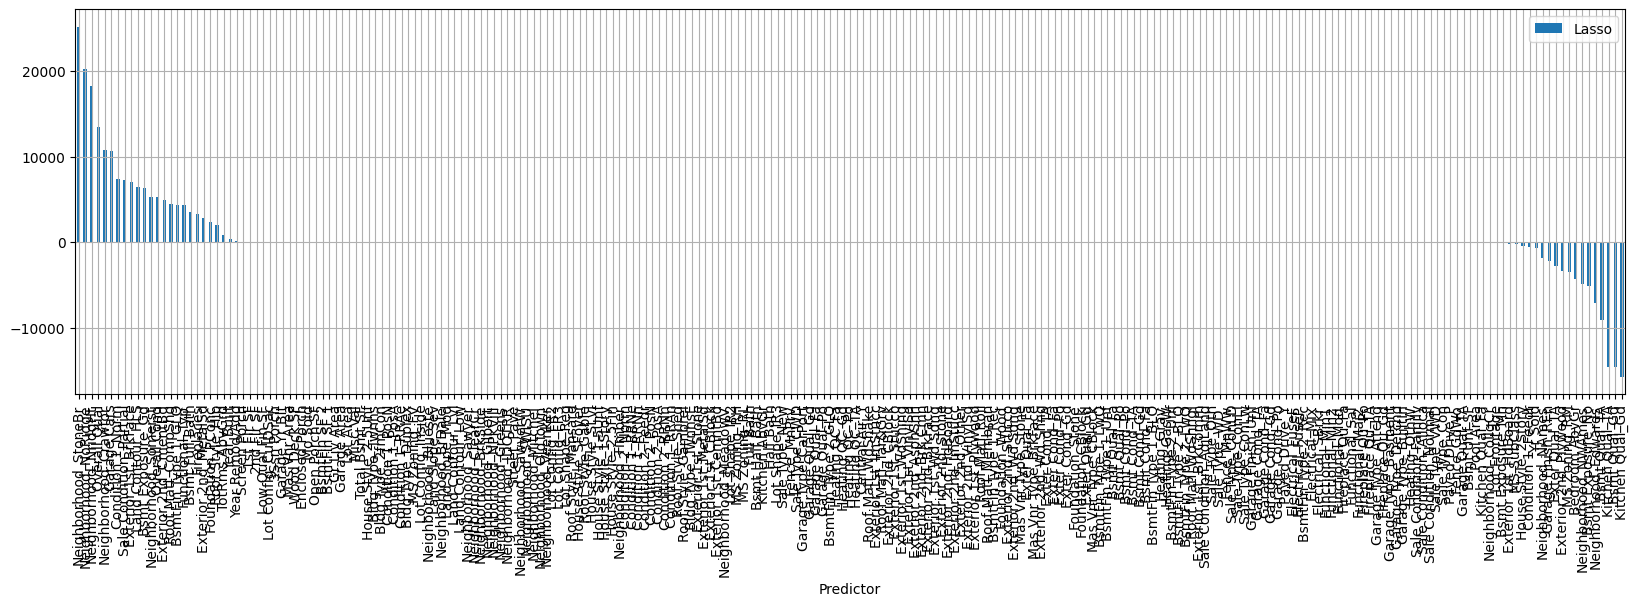

In [122]:
# Plot model coefficients
model_results = pd.DataFrame()
model_results['Predictor'] = X_all_features.columns
model_results['Lasso'] = model_lasso.coef_
model_results.sort_values( by = ["Lasso"], ascending = False ).plot(
    x = 'Predictor',
    kind = 'bar',
    figsize = (20,5)
    )
plt.grid()

In [123]:
model_results['Lasso'].abs().sort_values()

,Lasso
21,0.000000
19,0.000000
18,0.000000
17,0.000000
52,0.000000
...,...
156,14632.993814
189,15761.016465
69,18264.819769
68,20255.659925


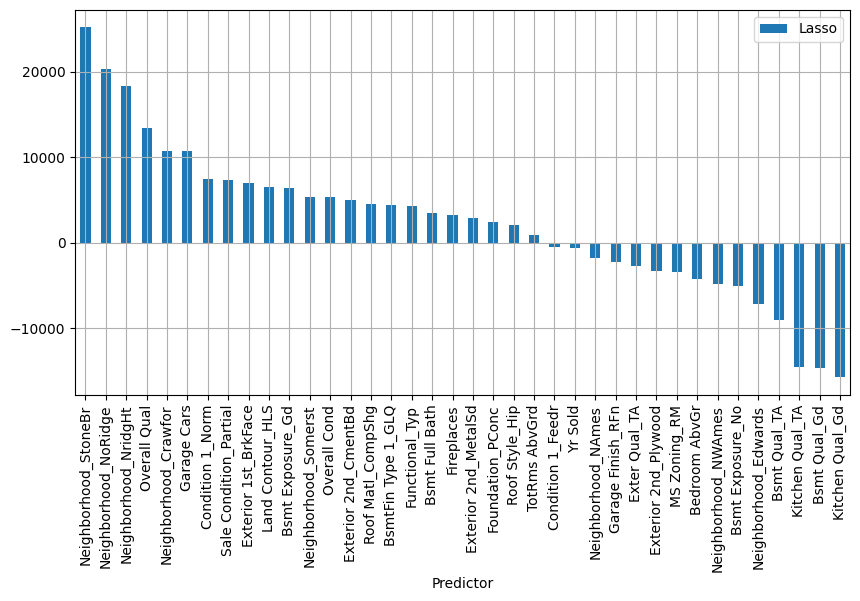

In [124]:
# Plot parameters with coefficients greater than 0
greater_0 = model_results[(model_results['Lasso'] > 500 ) | (model_results['Lasso'] < -500 )]
greater_0.sort_values( by = ["Lasso"], ascending = False ).plot(x = 'Predictor', kind = 'bar', figsize = (10,5))
plt.grid()

In [125]:
X_features_work = X_all_features[greater_0["Predictor"]]

### Working Data Frame

In [126]:
df_work = pd.concat([df_clean[target_col], X_features_work], axis=1).reset_index(drop=True)

In [127]:
df_work

,SalePrice,Overall Qual,Overall Cond,Bsmt Full Bath,Bedroom AbvGr,TotRms AbvGrd,Fireplaces,Garage Cars,Yr Sold,MS Zoning_RM,...,Bsmt Qual_Gd,Bsmt Qual_TA,Bsmt Exposure_Gd,Bsmt Exposure_No,BsmtFin Type 1_GLQ,Kitchen Qual_Gd,Kitchen Qual_TA,Functional_Typ,Garage Finish_RFn,Sale Condition_Partial
0,115400,4,3,1.0,3,5,0,2.0,2007,0,...,0,1,0,1,0,0,1,1,0,0
1,141000,6,6,0.0,3,6,1,1.0,2007,1,...,0,1,0,1,0,1,0,1,0,0
2,254000,8,5,1.0,3,7,1,2.0,2010,0,...,1,0,0,1,1,1,0,1,1,0
3,155000,7,9,1.0,3,6,0,2.0,2009,0,...,1,0,0,1,0,1,0,1,1,0
4,125000,5,5,0.0,3,5,1,1.0,2010,0,...,0,1,0,1,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1979,114500,6,6,0.0,3,6,1,2.0,2006,1,...,0,1,0,1,0,0,1,1,0,0
1980,162000,7,6,1.0,1,4,0,2.0,2009,0,...,1,0,0,1,1,1,0,1,0,0
1981,211500,8,5,1.0,1,4,2,2.0,2009,0,...,1,0,1,0,1,1,0,1,0,0
1982,165000,6,5,0.0,3,7,1,2.0,2009,0,...,1,0,0,1,0,0,1,1,1,0


## Data Processing

#### Performance

Performance metric is RMSPE

In [128]:
# Define a function to calculate RMSPE
def rmspe(y_true, y_pred):
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2)) * 100


##### Linear Regression

In [129]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features_work,
        y_target,
        test_size=0.25,
        random_state=None
    )

    # Create an empty LR model
    modelLR = LinearRegression()

    # Train ( fit ) the model
    modelLR.fit( (X_train), y_train)

    # Make predicitons using the model
    y_pred = modelLR.predict(X_test)

    # calculate the accuracy
    results[i] = rmspe(y_test, y_pred)

results

array([17.10647831, 20.78229561, 20.55079189, 16.71083789, 18.6384223 ,
       18.58455161, 17.94342795, 23.84007803, 16.73519636, 19.6779876 ,
       20.40820466, 19.67214087, 18.68533533, 23.52778756, 19.0654888 ,
       23.86966083, 17.56776354, 19.70528484, 23.362106  , 18.1554507 ,
       18.76281703, 18.96879097, 16.76913312, 18.27489228, 18.59864324,
       19.16028983, 17.65925736, 17.90123015, 22.47005039, 21.60032778,
       16.68986896, 24.65436986, 23.86867668, 19.61907726, 19.30051856,
       21.46369773, 23.31263687, 17.81321233, 23.47197815, 19.05949064,
       19.06502695, 18.84511782, 18.08702943, 18.45060344, 20.25737241,
       20.70341684, 19.56296285, 22.89948795, 17.76590934, 17.99493716,
       19.5643606 , 14.98769073, 19.74560331, 17.9621408 , 24.35070203,
       25.69413361, 19.23204763, 27.25481201, 19.1927251 , 24.14963921,
       21.03887058, 22.08773174, 26.42540045, 23.99081164, 23.66350052,
       20.16406121, 19.67570892, 18.92344092, 20.62164347, 18.25

''

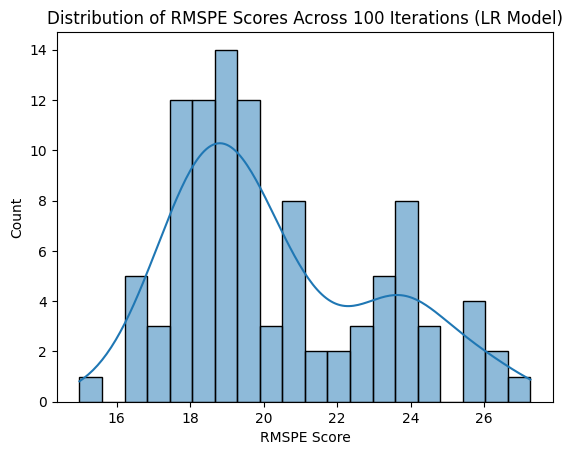

In [130]:
# Display a histogram of the multi CV results
sns.histplot(results, kde=True, bins=20)
plt.title('Distribution of RMSPE Scores Across 100 Iterations (LR Model)')
plt.xlabel('RMSPE Score')
plt.ylabel('Count')
;

#### Transformation

Box Cox (Transformation of Response)

In [131]:
X_train, X_test, y_train, y_test = train_test_split(X_features_work,y_target,test_size=0.2, random_state = 4)
fitted_data, fitted_lambda = stats.boxcox(y_train)
print(fitted_lambda)


-0.05480421516029014


In [132]:
y_train.mean() , y_train.median()

(np.float64(184665.47826086957), 163000.0)

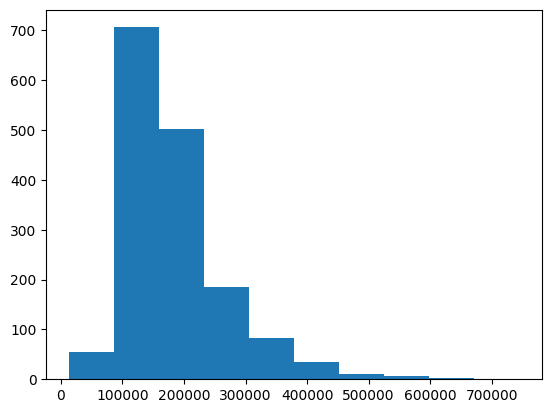

In [133]:
plt.hist(y_train) ;

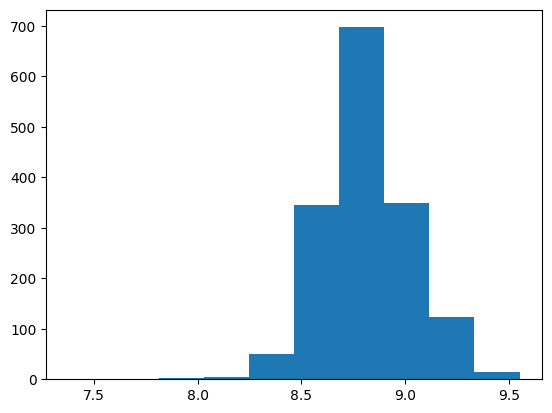

In [134]:
plt.hist(fitted_data) ;

In [135]:
fitted_data.mean() , pd.Series(fitted_data).median()

(np.float64(8.813624333560533), 8.794500183464038)

## One cross validation


In [136]:
X_train, X_test, y_train, y_test = train_test_split(X_features_work,y_target,test_size=0.2)

y_train[:].to_list()


[325000,
 145500,
 252000,
 386250,
 130000,
 132000,
 259000,
 85000,
 105900,
 185850,
 179200,
 125000,
 125500,
 105000,
 161000,
 119000,
 200000,
 139000,
 103000,
 94900,
 198600,
 134000,
 108538,
 145000,
 35000,
 106500,
 176000,
 128500,
 185088,
 116000,
 250000,
 176432,
 167000,
 462000,
 229000,
 116000,
 105000,
 148000,
 188000,
 150000,
 584500,
 99500,
 207000,
 128000,
 159900,
 176000,
 236500,
 336860,
 129000,
 115500,
 192000,
 419005,
 293000,
 105000,
 113500,
 148000,
 392000,
 383000,
 160000,
 150000,
 173500,
 332200,
 139500,
 143000,
 132000,
 227875,
 131500,
 117000,
 181000,
 155000,
 298751,
 269500,
 289000,
 165000,
 149000,
 145000,
 175500,
 155835,
 135000,
 239900,
 55000,
 184750,
 175000,
 130000,
 145400,
 470000,
 315750,
 132000,
 318000,
 410000,
 191000,
 485000,
 264500,
 116000,
 185000,
 183000,
 275500,
 91000,
 120000,
 375000,
 156500,
 132000,
 125000,
 89000,
 139000,
 136500,
 88000,
 133500,
 240000,
 144900,
 184000,
 128500,


In [137]:
# Perform the box cox transformation on y_train
fitted_data, fitted_lambda = stats.boxcox(y_train)

fitted_lambda, fitted_data

(np.float64(-0.030653082302859912),
 array([10.51411945,  9.9627147 , 10.34103875, ..., 10.38811214,
        10.15631878,  9.86805795]))

In [138]:
# Fit the linear regression model. Note: you can also perform box cox with Lasso or Ridge regression
model = sm.OLS(fitted_data, X_train).fit()
y_pred = model.predict(X_test)

y_pred[:].to_list()

[10.642533965504688,
 10.06011598448844,
 9.999638410925364,
 10.360858059521261,
 9.865653558762304,
 10.402631381059242,
 10.219241910923877,
 10.435620872213162,
 9.846459632498062,
 10.390703613313525,
 10.385767123255912,
 10.614649700874065,
 9.880078402308001,
 10.482190706391632,
 10.225509507256682,
 10.143355533832183,
 10.536873567904859,
 9.739318507914753,
 9.921197911083613,
 10.169520082807223,
 9.693854695702264,
 10.17794244504283,
 9.992914779560786,
 10.707468213126935,
 9.756733658371168,
 10.19657869329861,
 10.149452508148407,
 10.74914448318942,
 10.023680013816477,
 9.837820787274856,
 9.891300074990474,
 10.176053716992298,
 10.335961826919439,
 9.862819312225694,
 10.182805231163444,
 9.76672946511574,
 10.305077566624941,
 10.359447352728548,
 10.35632041365326,
 9.717897750788385,
 9.83837267908185,
 10.385468517476458,
 10.018383621607933,
 9.674469978941865,
 10.429284165603072,
 10.478290062808947,
 9.879593033141836,
 10.38767481776358,
 10.1008306588758

In [139]:
# Perform the inverse box cox to get predictions back on original scale
real_y_pred = special.inv_boxcox(y_pred, fitted_lambda)

real_y_pred.to_list()

[393020.05222819484,
 167452.9319771001,
 153450.3017798652,
 259422.85381531934,
 126562.99639660638,
 275815.31114687223,
 210943.93946699056,
 289513.2700576627,
 123129.5491638983,
 271028.6062047076,
 269072.6819393415,
 377096.6964848863,
 129208.18316522495,
 310053.9946463042,
 212878.19803897984,
 188911.41407613893,
 336102.9400420652,
 105650.67773886018,
 137065.78866508472,
 196226.7455995058,
 99026.6814088122,
 198643.17084446535,
 151969.93382901695,
 432843.94689810683,
 108307.5234017156,
 204099.64835640913,
 190590.55850006972,
 460574.49367683945,
 158866.3405836568,
 121615.68347417425,
 131305.3474976314,
 198098.6291522255,
 250134.01349379125,
 126049.85522749925,
 200052.277867145,
 109863.4900619161,
 239085.42102936437,
 258887.13306996578,
 257703.7280499458,
 102474.60865923722,
 121711.82056896364,
 268954.83670621715,
 157656.49526447844,
 96333.96429153894,
 286828.7557936674,
 308277.2806666537,
 129118.25759712151,
 269826.8136388386,
 177615.92589147

In [140]:
rmspe(y_test,real_y_pred)


np.float64(14.654454912184478)

## Multiple cross validation


In [141]:
# Perform CV
n = 500
results = np.zeros(n)
for idx in range(n):
  X_train, X_test, y_train, y_test = train_test_split(X_features_work,y_target,test_size=0.2)

  # Perform the box cox transformation on y_train
  fitted_data, fitted_lambda = stats.boxcox(y_train)

  # Fit the linear regression model. Note: you can also perform box cox with Lasso or Ridge regression
  model = sm.OLS(fitted_data, X_train).fit()
  y_pred = model.predict(X_test)

  # Perform the inverse box cox to get predictions back on original scale
  real_y_pred = special.inv_boxcox(y_pred, fitted_lambda)

  results[idx] = rmspe(y_test,real_y_pred)
print(f"CV RMSPE: {results.mean().round(2)*1000}")

CV RMSPE: 19310.0


## Data Visualization

#### Residual Analysis

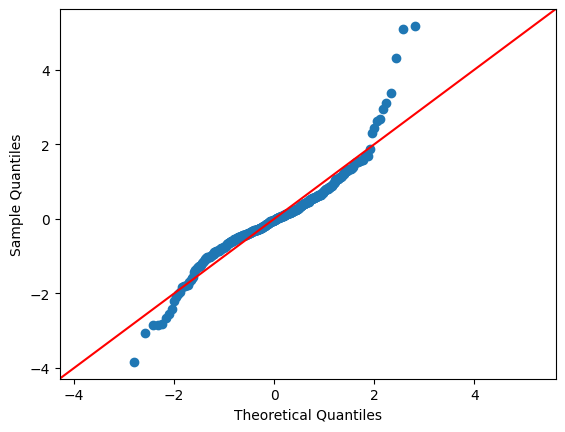

In [142]:
# QQ Plot - Residuals are not normally distributed
res = y_test - real_y_pred
sm.qqplot(res, fit=True, line="45") ;

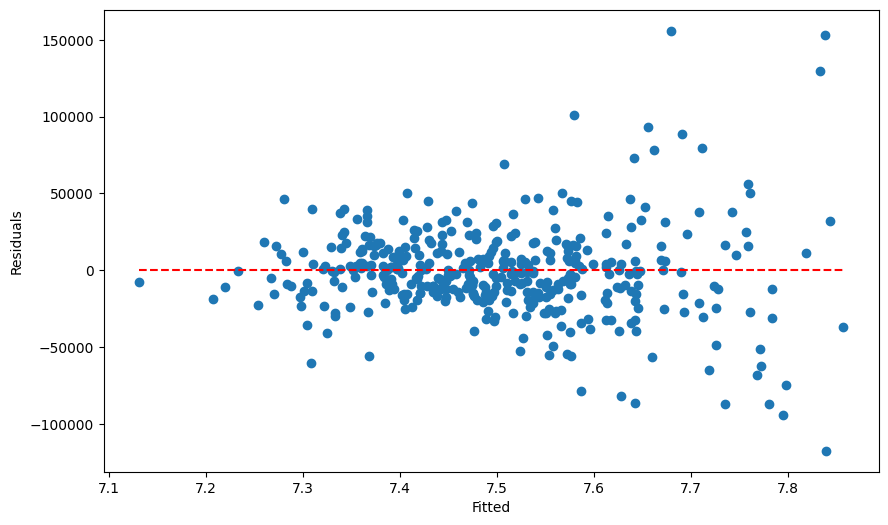

In [143]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

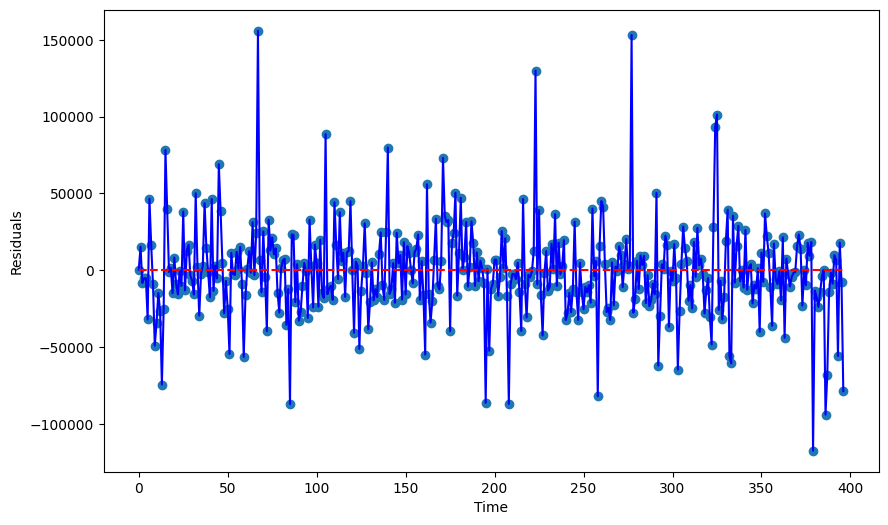

In [144]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

In [145]:
# Prediction performance stats
print("Mean RMSPE:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum RMSPE:", np.min(results))
print("Maximum RMSPE:", np.max(results))

Mean RMSPE: 19.30963880017541
Standard deviation: 5.520663843248576
Minimum RMSPE: 12.917099391807705
Maximum RMSPE: 37.135825397474036


## Communication of Results

#### Conclusion

Using all features and lasso for feature selection, the linear regression model produced a the same RMSPE as pass 17 after performing a box cox transformation. Lower score of 19 compared to previous pass at 20 RMSPE.



#### Future Work


- Try different feature selection method
- Try a different prediction model
- Try getting RMPSE lower